# First Backtest: SMA Crossover on SPY

**Rules**:
- `fast = 50` days, `slow = 200` days (the classic "Golden Cross" / "Death Cross")
- Long-only (flat when fast SMA ≤ slow SMA)
- Transaction cost: **5 bps** one-way

All logic lives in `quantlab`; this notebook is imports + plots only.


In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import yfinance as yf

from quantlab.backtest.engine import run_backtest
from quantlab.metrics import drawdown, simple_returns

warnings.filterwarnings('ignore')  # suppress yfinance / pandas FutureWarning noise
plt.style.use('seaborn-v0_8-darkgrid')
FIGSIZE = (13, 5)


## Parameters

In [2]:
TICKER   = 'SPY'
START    = '2010-01-01'
END      = '2024-12-31'
FAST     = 50
SLOW     = 200
COST_BPS = 5.0


## 1 · Download price data

In [3]:
raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
prices = raw['Close'].squeeze().dropna()
prices.name = TICKER
print(f'Downloaded {len(prices):,} trading days  '
      f'({prices.index[0].date()} → {prices.index[-1].date()})')
prices.tail(3)


Cookie fetch from fc.yahoo.com failed (ConnectionError), continuing without it


Downloaded 3,773 trading days  (2010-01-04 → 2024-12-30)


Date
2024-12-26    589.753967
2024-12-27    583.545837
2024-12-30    576.886719
Name: SPY, dtype: float64

## 2 · Run the backtest

In [4]:
result = run_backtest(prices, fast=FAST, slow=SLOW, cost_bps=COST_BPS)

# Build buy-and-hold equity over the same date range as the strategy
asset_ret = simple_returns(prices)
bah_equity = (1 + asset_ret).cumprod()

print('\n=== Strategy metrics ===')
for k, v in result.metrics.items():
    print(f'  {k:<15} {v:+.4f}')
print(f'  {"n_trades":<15} {result.n_trades}')



=== Strategy metrics ===
  cagr            +0.0951
  vol             +0.1367
  sharpe          +0.7333
  max_drawdown    -0.3372
  total_cost      +0.0065
  n_trades        13


## 3 · Equity curve vs buy-and-hold

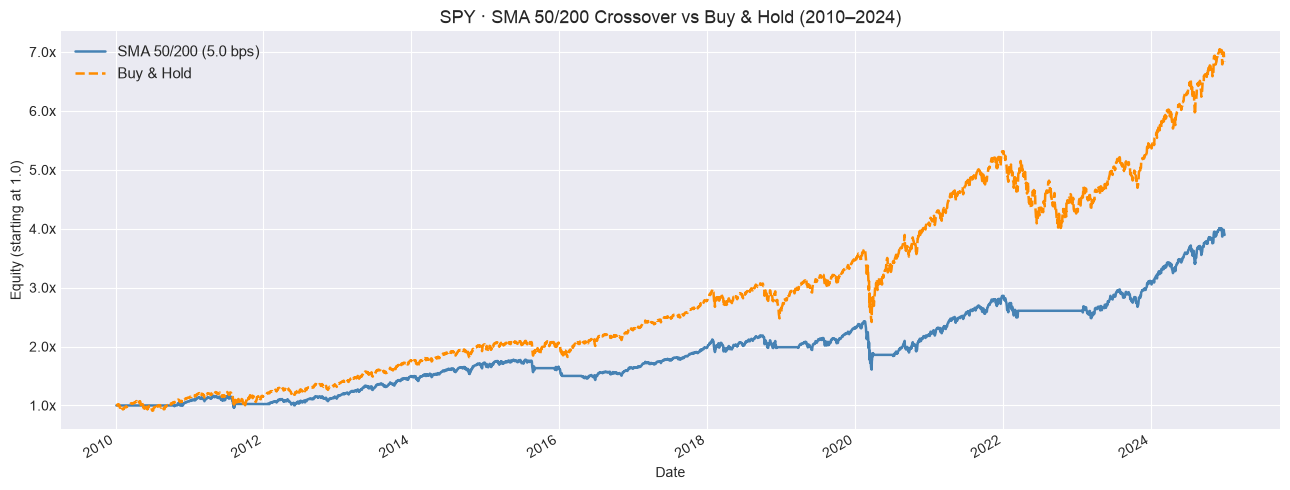

In [5]:
fig, ax = plt.subplots(figsize=FIGSIZE)

result.equity.plot(ax=ax, label=f'SMA {FAST}/{SLOW} ({COST_BPS} bps)', lw=1.8, color='steelblue')
bah_equity.plot(ax=ax, label='Buy & Hold', lw=1.8, linestyle='--', color='darkorange')

ax.set_title(f'{TICKER} · SMA {FAST}/{SLOW} Crossover vs Buy & Hold ({START[:4]}–{END[:4]})', fontsize=13)
ax.set_ylabel('Equity (starting at 1.0)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.1f}x'))
ax.legend(fontsize=11)
fig.tight_layout()
plt.savefig('../docs/equity_curve.png', dpi=150)
plt.show()


## 4 · Drawdown

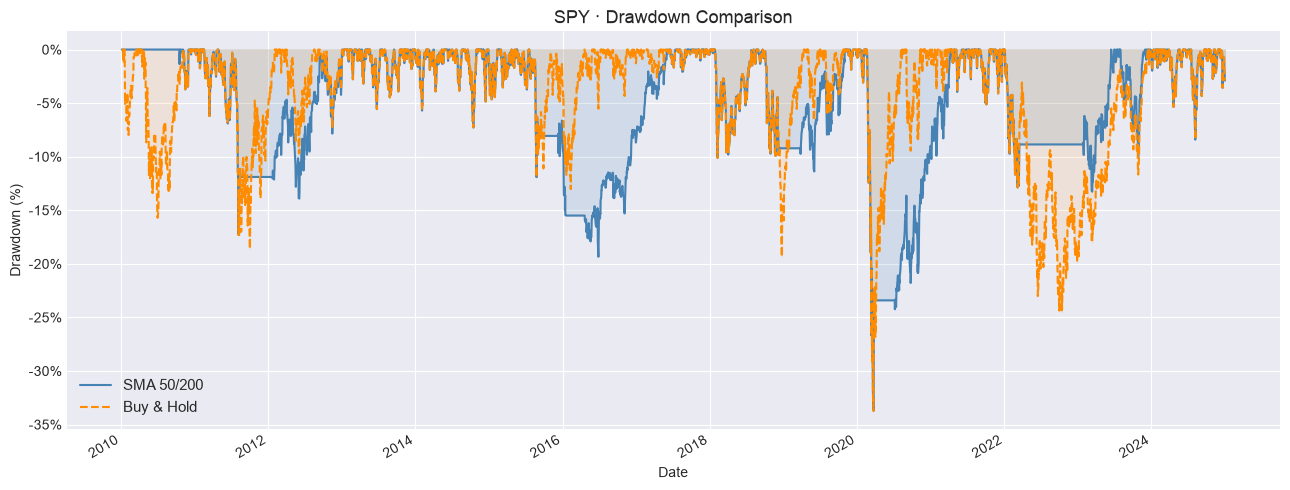

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE)

strat_dd  = drawdown(result.equity) * 100
bah_dd    = drawdown(bah_equity) * 100

strat_dd.plot(ax=ax, label=f'SMA {FAST}/{SLOW}', lw=1.5, color='steelblue')
bah_dd.plot(ax=ax, label='Buy & Hold', lw=1.5, linestyle='--', color='darkorange')

ax.set_title(f'{TICKER} · Drawdown Comparison', fontsize=13)
ax.set_ylabel('Drawdown (%)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
ax.legend(fontsize=11)
ax.fill_between(strat_dd.index, strat_dd, 0, alpha=0.15, color='steelblue')
ax.fill_between(bah_dd.index, bah_dd, 0, alpha=0.10, color='darkorange')
fig.tight_layout()
plt.savefig('../docs/drawdown.png', dpi=150)
plt.show()


## 5 · Side-by-side metrics

In [7]:
from quantlab.metrics import annualized_vol, cagr, max_drawdown, sharpe

def summarise(label, returns, equity):
    return {
        'Strategy': label,
        'CAGR':          f'{cagr(returns):+.2%}',
        'Ann. Vol':      f'{annualized_vol(returns):.2%}',
        'Sharpe':        f'{sharpe(returns):.2f}',
        'Max Drawdown':  f'{max_drawdown(equity):.2%}',
    }

rows = [
    summarise(f'SMA {FAST}/{SLOW} ({COST_BPS} bps)', result.returns, result.equity),
    summarise('Buy & Hold',                          asset_ret,      bah_equity),
]
pd.DataFrame(rows).set_index('Strategy')


,CAGR,Ann. Vol,Sharpe,Max Drawdown
Strategy,,,,
SMA 50/200 (5.0 bps),+9.51%,13.67%,0.73,-33.72%
Buy & Hold,+13.70%,17.05%,0.84,-33.72%
